<a href="https://colab.research.google.com/github/wudii456/415-SVRDD-Road-Damage-Detection-Project/blob/main/svrdd_main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SVRDD Road Damage Detection

The Setup part is a must before working on the project. Run the cells **one by one, top to bottom** (do not use *Run all*).

**Before making changes:**
- GPU: *Runtime → Change runtime type* → **T4** for tests, **A100** for the real training runs
- Left Menu 🔑 **Secrets**: there should be a `GITHUB_TOKEN` and *Notebook access* must be on (each team member adds his or her own token)
- In **1. Setup**, set your own name and the **BRANCH** you will work on

## 1. Setup

**What is BRANCH?** Your own copy of the repo.
- `main` is the shared version that is **known to work**. Do not experiment on it directly.
- To try something new (Group DRO, a new augmentation...), write your own branch name, e.g. `feature/group-dro` or `feature/augment-yigit`. If it does not exist yet, it is created automatically from `main`.
- For plain baseline runs, `main` is fine.

In [1]:
GH_USER   = 'wudii456'
REPO      = '415-SVRDD-Road-Damage-Detection-Project'
BRANCH    = 'main'                     # e.g. 'feature/group-dro'
GIT_NAME  = 'Yiğit Emre Arıkan'
GIT_EMAIL = 'yigitemrea@hotmail.com'
DRIVE_DIR = '/content/drive/MyDrive/svrdd'   # shared Drive folder: data cache, runs, experiment log

In [2]:
import os, subprocess
os.environ['WANDB_MODE'] = 'disabled'
from google.colab import userdata, drive

drive.mount('/content/drive')
os.environ['GITHUB_TOKEN'] = userdata.get('GITHUB_TOKEN')
os.environ['GH_USER'] = GH_USER
os.environ['REPO'] = REPO
PROJECT = f'/content/{REPO}'

def git(*args, check=True):
    """Run a git command inside the project repo and return the result."""
    return subprocess.run(['git', '-C', PROJECT, *args], check=check, capture_output=True, text=True)

# Download the repo (or update it if it is already here)
if not os.path.exists(PROJECT):
    url = f"https://{os.environ['GITHUB_TOKEN']}@github.com/{GH_USER}/{REPO}.git"
    subprocess.run(['git', 'clone', '-q', url, PROJECT], check=True)
git('config', 'user.name', GIT_NAME)
git('config', 'user.email', GIT_EMAIL)
git('fetch', '-q', 'origin')

# Switch to the chosen branch (create it from main if it does not exist yet)
if f'origin/{BRANCH}' in git('branch', '-r').stdout:
    git('checkout', '-q', BRANCH)
    git('pull', '-q', 'origin', BRANCH)
else:
    git('checkout', '-q', '-b', BRANCH, 'origin/main')
    git('push', '-q', '-u', 'origin', BRANCH)
    print(f'Created new branch: {BRANCH}')

%cd {PROJECT}/yolov5
!pip install -q -r requirements.txt

import torch
print('GPU   :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NO GPU EXISTING!')
print('Branch:', git('rev-parse', '--abbrev-ref', 'HEAD').stdout.strip())
print('Commit:', git('log', '--oneline', '-1').stdout.strip())

Mounted at /content/drive
/content/415-SVRDD-Road-Damage-Detection-Project/yolov5
GPU   : NVIDIA A100-SXM4-40GB
Branch: main
Commit: af93934 Add data audit script used in the progress report


## 2. Prepare the dataset

The first time, the data is downloaded from Zenodo to Drive; later sessions only extract it from Drive.

In [6]:
import os, shutil, requests, subprocess

DATA_DIR  = '/content/datasets/svrdd'
CACHE_DIR = f'{DRIVE_DIR}/zenodo'
DONE_FLAG = f'{DATA_DIR}/.extracted_ok'
os.makedirs(CACHE_DIR, exist_ok=True)

# 1) Download to Drive only if missing or incomplete
rec = requests.get('https://zenodo.org/api/records/10100129').json()
files = [(f['key'], f['links']['self'], f['size']) for f in rec['files']]
for name, url, size in files:
    path = f'{CACHE_DIR}/{name}'
    if os.path.exists(path) and os.path.getsize(path) == size:
        print(f'Already on Drive: {name}')
    else:
        print(f'Downloading from Zenodo (first time only): {name} ({size/1e9:.2f} GB)')
        subprocess.run(['wget', '-q', '--show-progress', '-O', path, url], check=True)

# 2) Extract into /content only if a previous extraction did not finish
if not os.path.exists(DONE_FLAG):
    shutil.rmtree(DATA_DIR, ignore_errors=True)
    os.makedirs(DATA_DIR)
    for name, _, _ in files:
        print(f'Extracting: {name}')
        subprocess.run(['unzip', '-q', '-o', f'{CACHE_DIR}/{name}', '-d', DATA_DIR], check=True)
    open(DONE_FLAG, 'w').close()
    print('Extraction complete.')
else:
    print('Dataset already extracted.')

!find {DATA_DIR} -maxdepth 3 -type d

Already on Drive: SVRDD_YOLO.zip
Already on Drive: SVRDD_VOC.zip
Extracting: SVRDD_YOLO.zip
Extracting: SVRDD_VOC.zip
Extraction complete.
/content/datasets/svrdd
/content/datasets/svrdd/SVRDD_YOLO
/content/datasets/svrdd/SVRDD_YOLO/Chaoyang
/content/datasets/svrdd/SVRDD_YOLO/Chaoyang/labels
/content/datasets/svrdd/SVRDD_YOLO/Chaoyang/images
/content/datasets/svrdd/SVRDD_YOLO/Dongcheng
/content/datasets/svrdd/SVRDD_YOLO/Dongcheng/labels
/content/datasets/svrdd/SVRDD_YOLO/Dongcheng/images
/content/datasets/svrdd/SVRDD_YOLO/Xicheng
/content/datasets/svrdd/SVRDD_YOLO/Xicheng/labels
/content/datasets/svrdd/SVRDD_YOLO/Xicheng/images
/content/datasets/svrdd/SVRDD_YOLO/Haidian
/content/datasets/svrdd/SVRDD_YOLO/Haidian/labels
/content/datasets/svrdd/SVRDD_YOLO/Haidian/images
/content/datasets/svrdd/SVRDD_YOLO/Fengtai
/content/datasets/svrdd/SVRDD_YOLO/Fengtai/labels
/content/datasets/svrdd/SVRDD_YOLO/Fengtai/images
/content/datasets/svrdd/SVRDD_VOC
/content/datasets/svrdd/SVRDD_VOC/Chaoyang
/

### 2a. Dataset inspection (optional, for the data audit)

Not needed every session. Shows split files, counts per district, class IDs and class names.

In [7]:
import os, glob, collections

ROOT = '/content/datasets/svrdd'
IMG_EXT = ('.jpg', '.jpeg', '.png')

# 1) Every file that is NOT an image or a YOLO label (split lists, class names, readme...)
print("=== Non-image / non-label files ===")
for p in sorted(glob.glob(f'{ROOT}/**/*', recursive=True)):
    if os.path.isfile(p) and not p.lower().endswith(IMG_EXT) and '/labels/' not in p and '/Annotations/' not in p:
        print(p, f'({os.path.getsize(p)/1e3:.1f} KB)')

# 2) Folder tree (directories only)
print("\n=== Directories ===")
for d in sorted({os.path.dirname(p) for p in glob.glob(f'{ROOT}/**/*', recursive=True)}):
    print(d)

# 3) Image / label counts per district (YOLO version)
print("\n=== Counts per district (SVRDD_YOLO) ===")
tot_img = tot_lbl = 0
for d in sorted(glob.glob(f'{ROOT}/SVRDD_YOLO/*/')):
    n_img = len([f for f in os.listdir(f'{d}images') if f.lower().endswith(IMG_EXT)]) if os.path.isdir(f'{d}images') else 0
    n_lbl = len(glob.glob(f'{d}labels/*.txt'))
    tot_img += n_img; tot_lbl += n_lbl
    print(f'{os.path.basename(d.rstrip("/")):12s} images={n_img:5d} labels={n_lbl:5d}')
print(f'{"TOTAL":12s} images={tot_img:5d} labels={tot_lbl:5d}')

# 4) Class ID histogram over all YOLO labels
print("\n=== Class ID counts (all YOLO labels) ===")
cls = collections.Counter()
for lf in glob.glob(f'{ROOT}/SVRDD_YOLO/*/labels/*.txt'):
    for line in open(lf):
        if line.strip():
            cls[line.split()[0]] += 1
for k in sorted(cls, key=lambda x: int(float(x))):
    print(f'class {k}: {cls[k]} boxes')
print('total boxes:', sum(cls.values()))

# 5) One example label file and one example image name
print("\n=== Example ===")
ex = sorted(glob.glob(f'{ROOT}/SVRDD_YOLO/*/labels/*.txt'))[0]
print('label file:', ex)
print(open(ex).read())
print('image names:', sorted(os.listdir(os.path.dirname(ex).replace('labels', 'images')))[:3])

# 6) Class names from the VOC XML files (to map IDs -> names)
print("\n=== Class names in VOC annotations ===")
import xml.etree.ElementTree as ET
names = collections.Counter()
for xf in glob.glob(f'{ROOT}/SVRDD_VOC/**/*.xml', recursive=True):
    for o in ET.parse(xf).getroot().iter('object'):
        names[o.findtext('name')] += 1
for n, c in names.most_common():
    print(f'{n}: {c} boxes')

=== Non-image / non-label files ===
/content/datasets/svrdd/SVRDD_YOLO/test.txt (69.5 KB)
/content/datasets/svrdd/SVRDD_YOLO/train.txt (417.0 KB)
/content/datasets/svrdd/SVRDD_YOLO/val.txt (69.5 KB)

=== Directories ===
/content/datasets/svrdd
/content/datasets/svrdd/SVRDD_VOC
/content/datasets/svrdd/SVRDD_VOC/Chaoyang
/content/datasets/svrdd/SVRDD_VOC/Chaoyang/Annotations
/content/datasets/svrdd/SVRDD_VOC/Chaoyang/JPEGImages
/content/datasets/svrdd/SVRDD_VOC/Dongcheng
/content/datasets/svrdd/SVRDD_VOC/Dongcheng/Annotations
/content/datasets/svrdd/SVRDD_VOC/Dongcheng/JPEGImages
/content/datasets/svrdd/SVRDD_VOC/Fengtai
/content/datasets/svrdd/SVRDD_VOC/Fengtai/Annotations
/content/datasets/svrdd/SVRDD_VOC/Fengtai/JPEGImages
/content/datasets/svrdd/SVRDD_VOC/Haidian
/content/datasets/svrdd/SVRDD_VOC/Haidian/Annotations
/content/datasets/svrdd/SVRDD_VOC/Haidian/JPEGImages
/content/datasets/svrdd/SVRDD_VOC/Xicheng
/content/datasets/svrdd/SVRDD_VOC/Xicheng/Annotations
/content/datasets/svr

### 2b. Authors' split + `data/svrdd.yaml` (every session)

Expected: train 6000, val 1000, test 1000, missing 0, all overlaps 0, unused 0.

In [8]:
import os, glob

ROOT  = '/content/datasets/svrdd/SVRDD_YOLO'
SPLIT_OUT = '/content/datasets/svrdd/splits'
os.makedirs(SPLIT_OUT, exist_ok=True)

# Map every image file name -> absolute path
img_by_name = {os.path.basename(p): p for p in glob.glob(f'{ROOT}/*/images/*.jpg')}
print('Images found:', len(img_by_name))

# Show what the authors' split files look like
for s in ['train', 'val', 'test']:
    with open(f'{ROOT}/{s}.txt') as f:
        print(f'{s}.txt first line: {f.readline().strip()!r}')

# Rewrite each split as absolute image paths that YOLOv5 can read
splits = {}
for s in ['train', 'val', 'test']:
    lines = [l.strip() for l in open(f'{ROOT}/{s}.txt') if l.strip()]
    names = [os.path.basename(l.replace('\\', '/')) for l in lines]
    names = [n if n.lower().endswith('.jpg') else n + '.jpg' for n in names]
    found = [img_by_name[n] for n in names if n in img_by_name]
    missing = [n for n in names if n not in img_by_name]
    splits[s] = set(found)
    with open(f'{SPLIT_OUT}/{s}.txt', 'w') as f:
        f.write('\n'.join(found) + '\n')
    print(f'{s:5s}: listed={len(lines)}  found={len(found)}  missing={len(missing)}')
    if missing:
        print('   example missing:', missing[:3])

# Sanity checks: no image in two splits, every image used once
print('train∩val :', len(splits['train'] & splits['val']))
print('train∩test:', len(splits['train'] & splits['test']))
print('val∩test  :', len(splits['val'] & splits['test']))
print('unused images:', len(set(img_by_name.values()) - splits['train'] - splits['val'] - splits['test']))

# Write the YOLOv5 dataset config
yaml_text = f"""path: {SPLIT_OUT}
train: {SPLIT_OUT}/train.txt
val: {SPLIT_OUT}/val.txt
test: {SPLIT_OUT}/test.txt
nc: 7
names: ['longitudinal_crack', 'transverse_crack', 'alligator_crack', 'pothole',
        'manhole_cover', 'longitudinal_patch', 'transverse_patch']
"""
with open(f'{PROJECT}/yolov5/data/svrdd.yaml', 'w') as f:
    f.write(yaml_text)
print('\nWrote data/svrdd.yaml:\n' + yaml_text)

Images found: 8000
train.txt first line: 'Dongcheng\\images\\0100220000130817112619617J1_1296317400_482913700.jpg'
val.txt first line: 'Dongcheng\\images\\0100220000130808165806528J2_1296287300_483105900.jpg'
test.txt first line: 'Dongcheng\\images\\0100220000130808165812318J2_1296284700_483102900.jpg'
train: listed=6000  found=6000  missing=0
val  : listed=1000  found=1000  missing=0
test : listed=1000  found=1000  missing=0
train∩val : 0
train∩test: 0
val∩test  : 0
unused images: 0

Wrote data/svrdd.yaml:
path: /content/datasets/svrdd/splits
train: /content/datasets/svrdd/splits/train.txt
val: /content/datasets/svrdd/splits/val.txt
test: /content/datasets/svrdd/splits/test.txt
nc: 7
names: ['longitudinal_crack', 'transverse_crack', 'alligator_crack', 'pothole',
        'manhole_cover', 'longitudinal_patch', 'transverse_patch']



## 3. Training + automatic experiment log

In each run change the `NAME` and `SEED`. In comparisons the **BATCH size, EPOCHS and GPU type must be the same**. All results go to Drive.

**Naming:** `<method>_s<seed>`, e.g. `baseline_s0`, `stage1_s1`, `dro_eta0.01_s0`. If the name already exists, the cell stops, so nothing is overwritten by mistake (delete the old folder on Drive if it was a failed run).

When training finishes, one row is added automatically to the shared **`experiments.csv`** on Drive: who, when, branch, commit, settings, and the best epoch's scores.

In [9]:
NAME    = 'baseline_s0'
SEED    = 0
BATCH   = 32
EPOCHS  = 80
HYP     = 'data/hyps/hyp.scratch-low.yaml'
CACHE   = 'ram'       # 'ram' is faster if the session has enough RAM (e.g. A100)
WORKERS = 8
NOTES   = ''           # free text, e.g. 'first baseline'

import os, csv, datetime, torch, pandas as pd

RUNS_DIR = f'{DRIVE_DIR}/runs'
RUN = f'{RUNS_DIR}/{NAME}'
assert not os.path.exists(RUN), f'{RUN} already exists. Pick a new NAME or delete the old (failed) folder.'

commit = git('rev-parse', '--short', 'HEAD').stdout.strip()
dirty  = bool(git('status', '--porcelain', '--untracked-files=no', '--', '.', ':!yolov5/data/svrdd.yaml').stdout.strip())
branch = git('rev-parse', '--abbrev-ref', 'HEAD').stdout.strip()
gpu    = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'
if dirty:
    print('WARNING: you have uncommitted code changes; push them (section 6) so this run can be reproduced.')

start = datetime.datetime.now()
!python train.py --img 640 --batch {BATCH} --epochs {EPOCHS} \
  --data data/svrdd.yaml --weights yolov5s.pt --hyp {HYP} \
  --seed {SEED} --cache {CACHE} --workers {WORKERS} \
  --name {NAME} --project {RUNS_DIR}
minutes = (datetime.datetime.now() - start).total_seconds() / 60

# ---- Append one row to the shared experiment log ----
row = dict(date=start.strftime('%Y-%m-%d %H:%M'), who=GIT_NAME, name=NAME, branch=branch,
           commit=commit + ('+dirty' if dirty else ''), hyp=HYP, seed=SEED, epochs=EPOCHS,
           batch=BATCH, gpu=gpu, minutes=round(minutes, 1), notes=NOTES)
res_file = f'{RUN}/results.csv'
if os.path.exists(res_file):
    df = pd.read_csv(res_file); df.columns = [c.strip() for c in df.columns]
    best = df.loc[df['metrics/mAP50-95'].idxmax()]
    pick = lambda *names: next(c for c in names if c in df.columns)
    m5095 = pick('metrics/mAP_0.5:0.95', 'metrics/mAP50-95')
    m50   = pick('metrics/mAP_0.5', 'metrics/mAP50')
    best = df.loc[df[m5095].idxmax()]
    row.update(status='done' if len(df) == EPOCHS else f'stopped at epoch {len(df)}',
               best_epoch=int(best['epoch']), P=round(best['metrics/precision'], 4),
               R=round(best['metrics/recall'], 4), mAP50=round(best[m50], 4),
               mAP50_95=round(best[m5095], 4))
else:
    row.update(status='failed')

log_file = f'{DRIVE_DIR}/experiments.csv'
new = not os.path.exists(log_file)
cols = ['date','who','name','status','branch','commit','hyp','seed','epochs','batch','gpu',
        'minutes','best_epoch','P','R','mAP50','mAP50_95','notes']
with open(log_file, 'a', newline='') as f:
    w = csv.DictWriter(f, fieldnames=cols)
    if new: w.writeheader()
    w.writerow({c: row.get(c, '') for c in cols})
print('Logged to experiments.csv:', row)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1795033661.340453    3017 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795033663.618512    3017 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_O

## 4. Check the results

Showing results from: /content/drive/MyDrive/svrdd/runs/baseline_s0


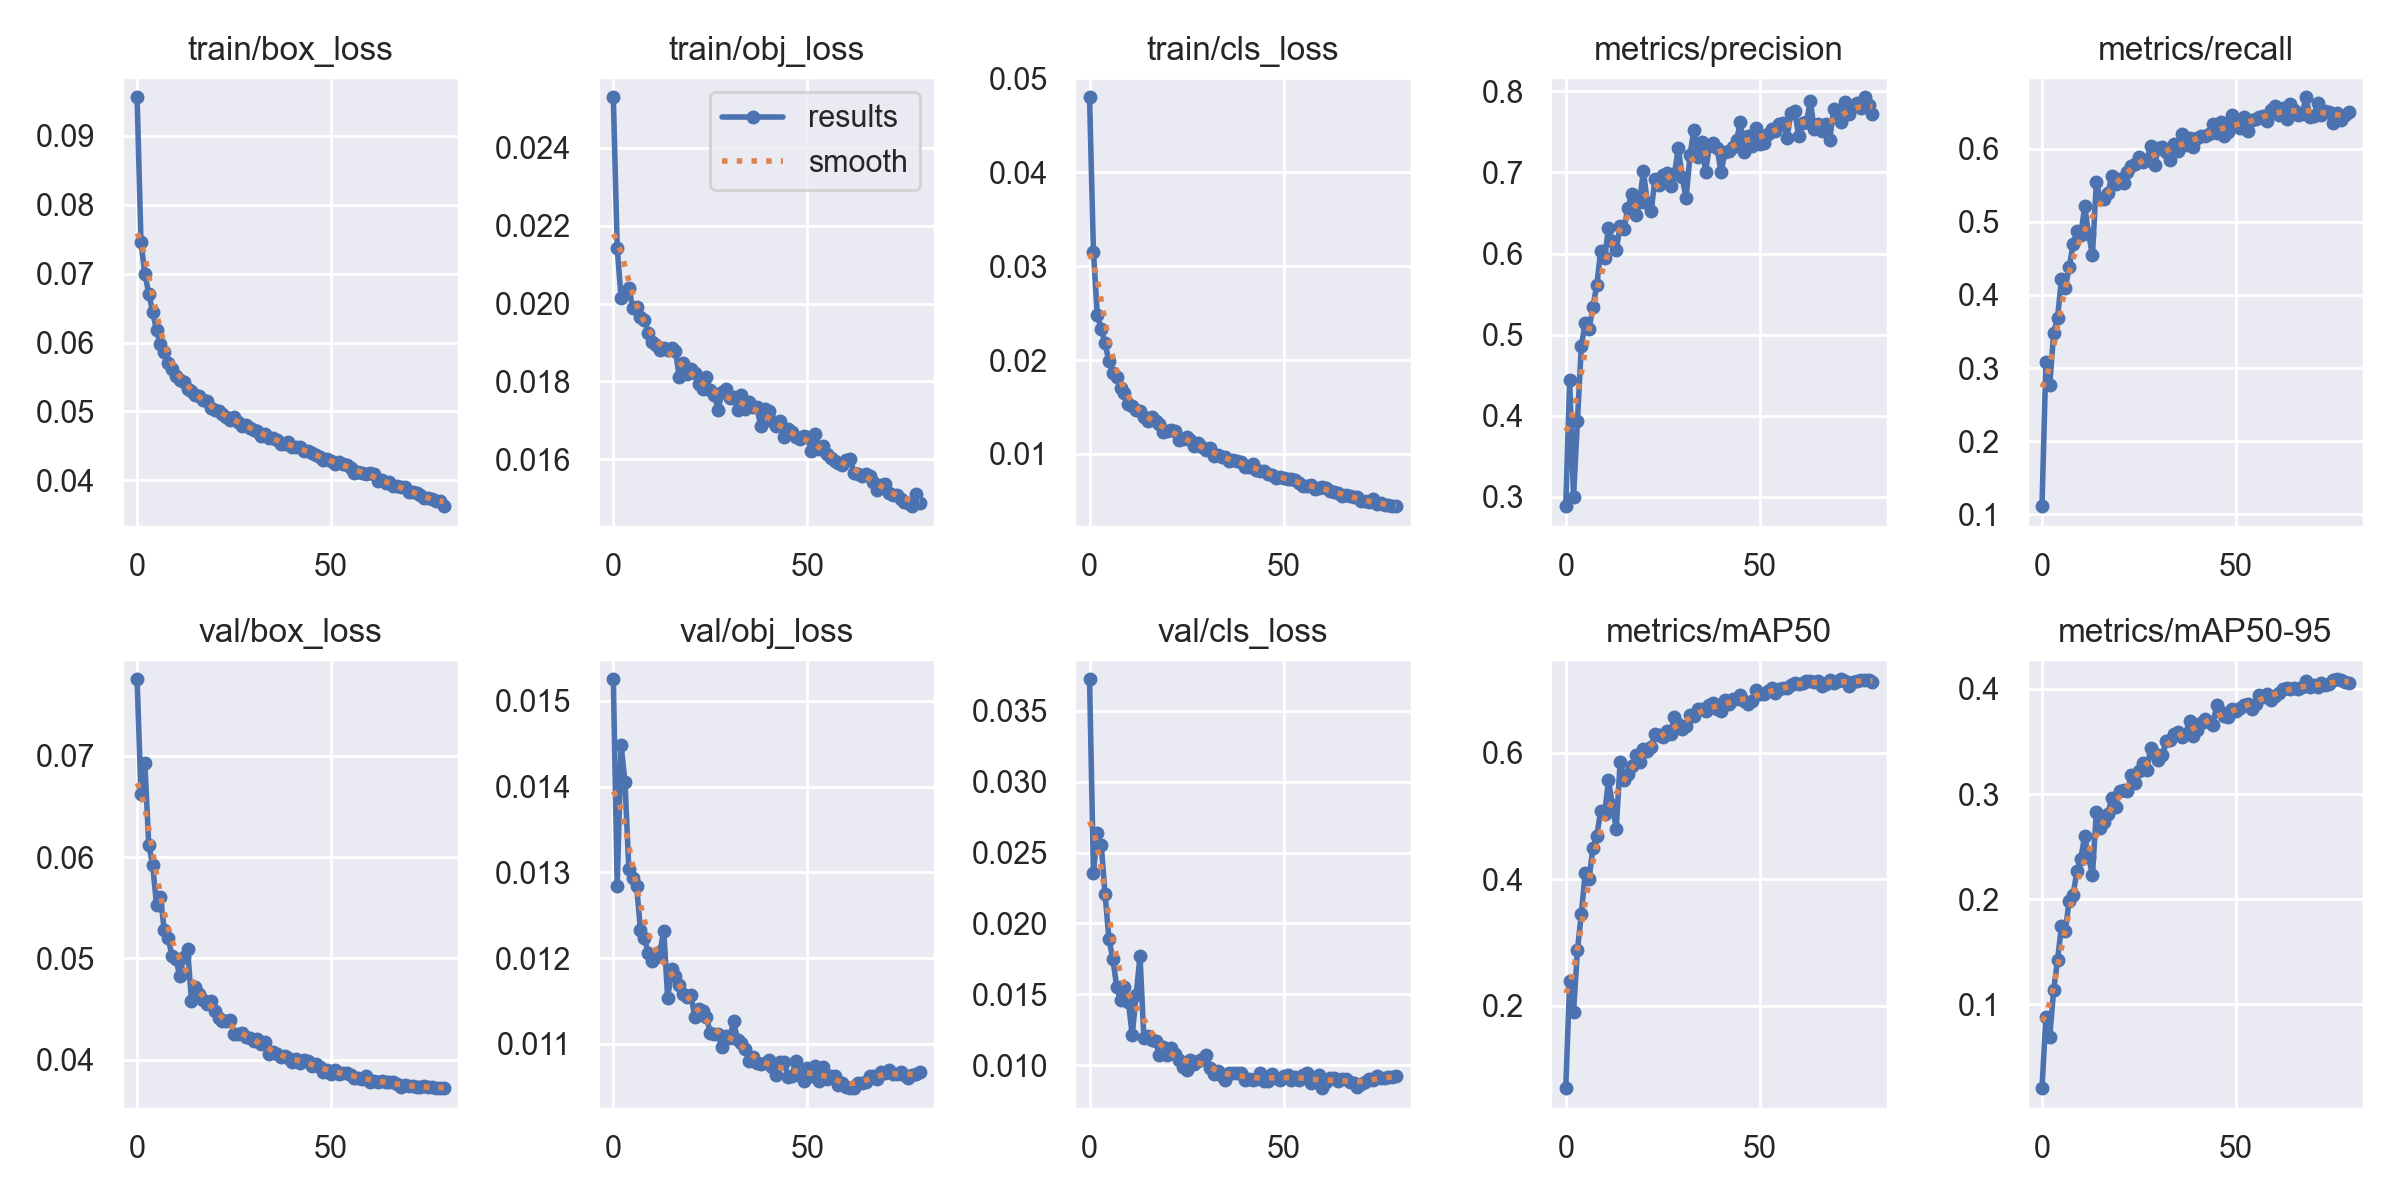

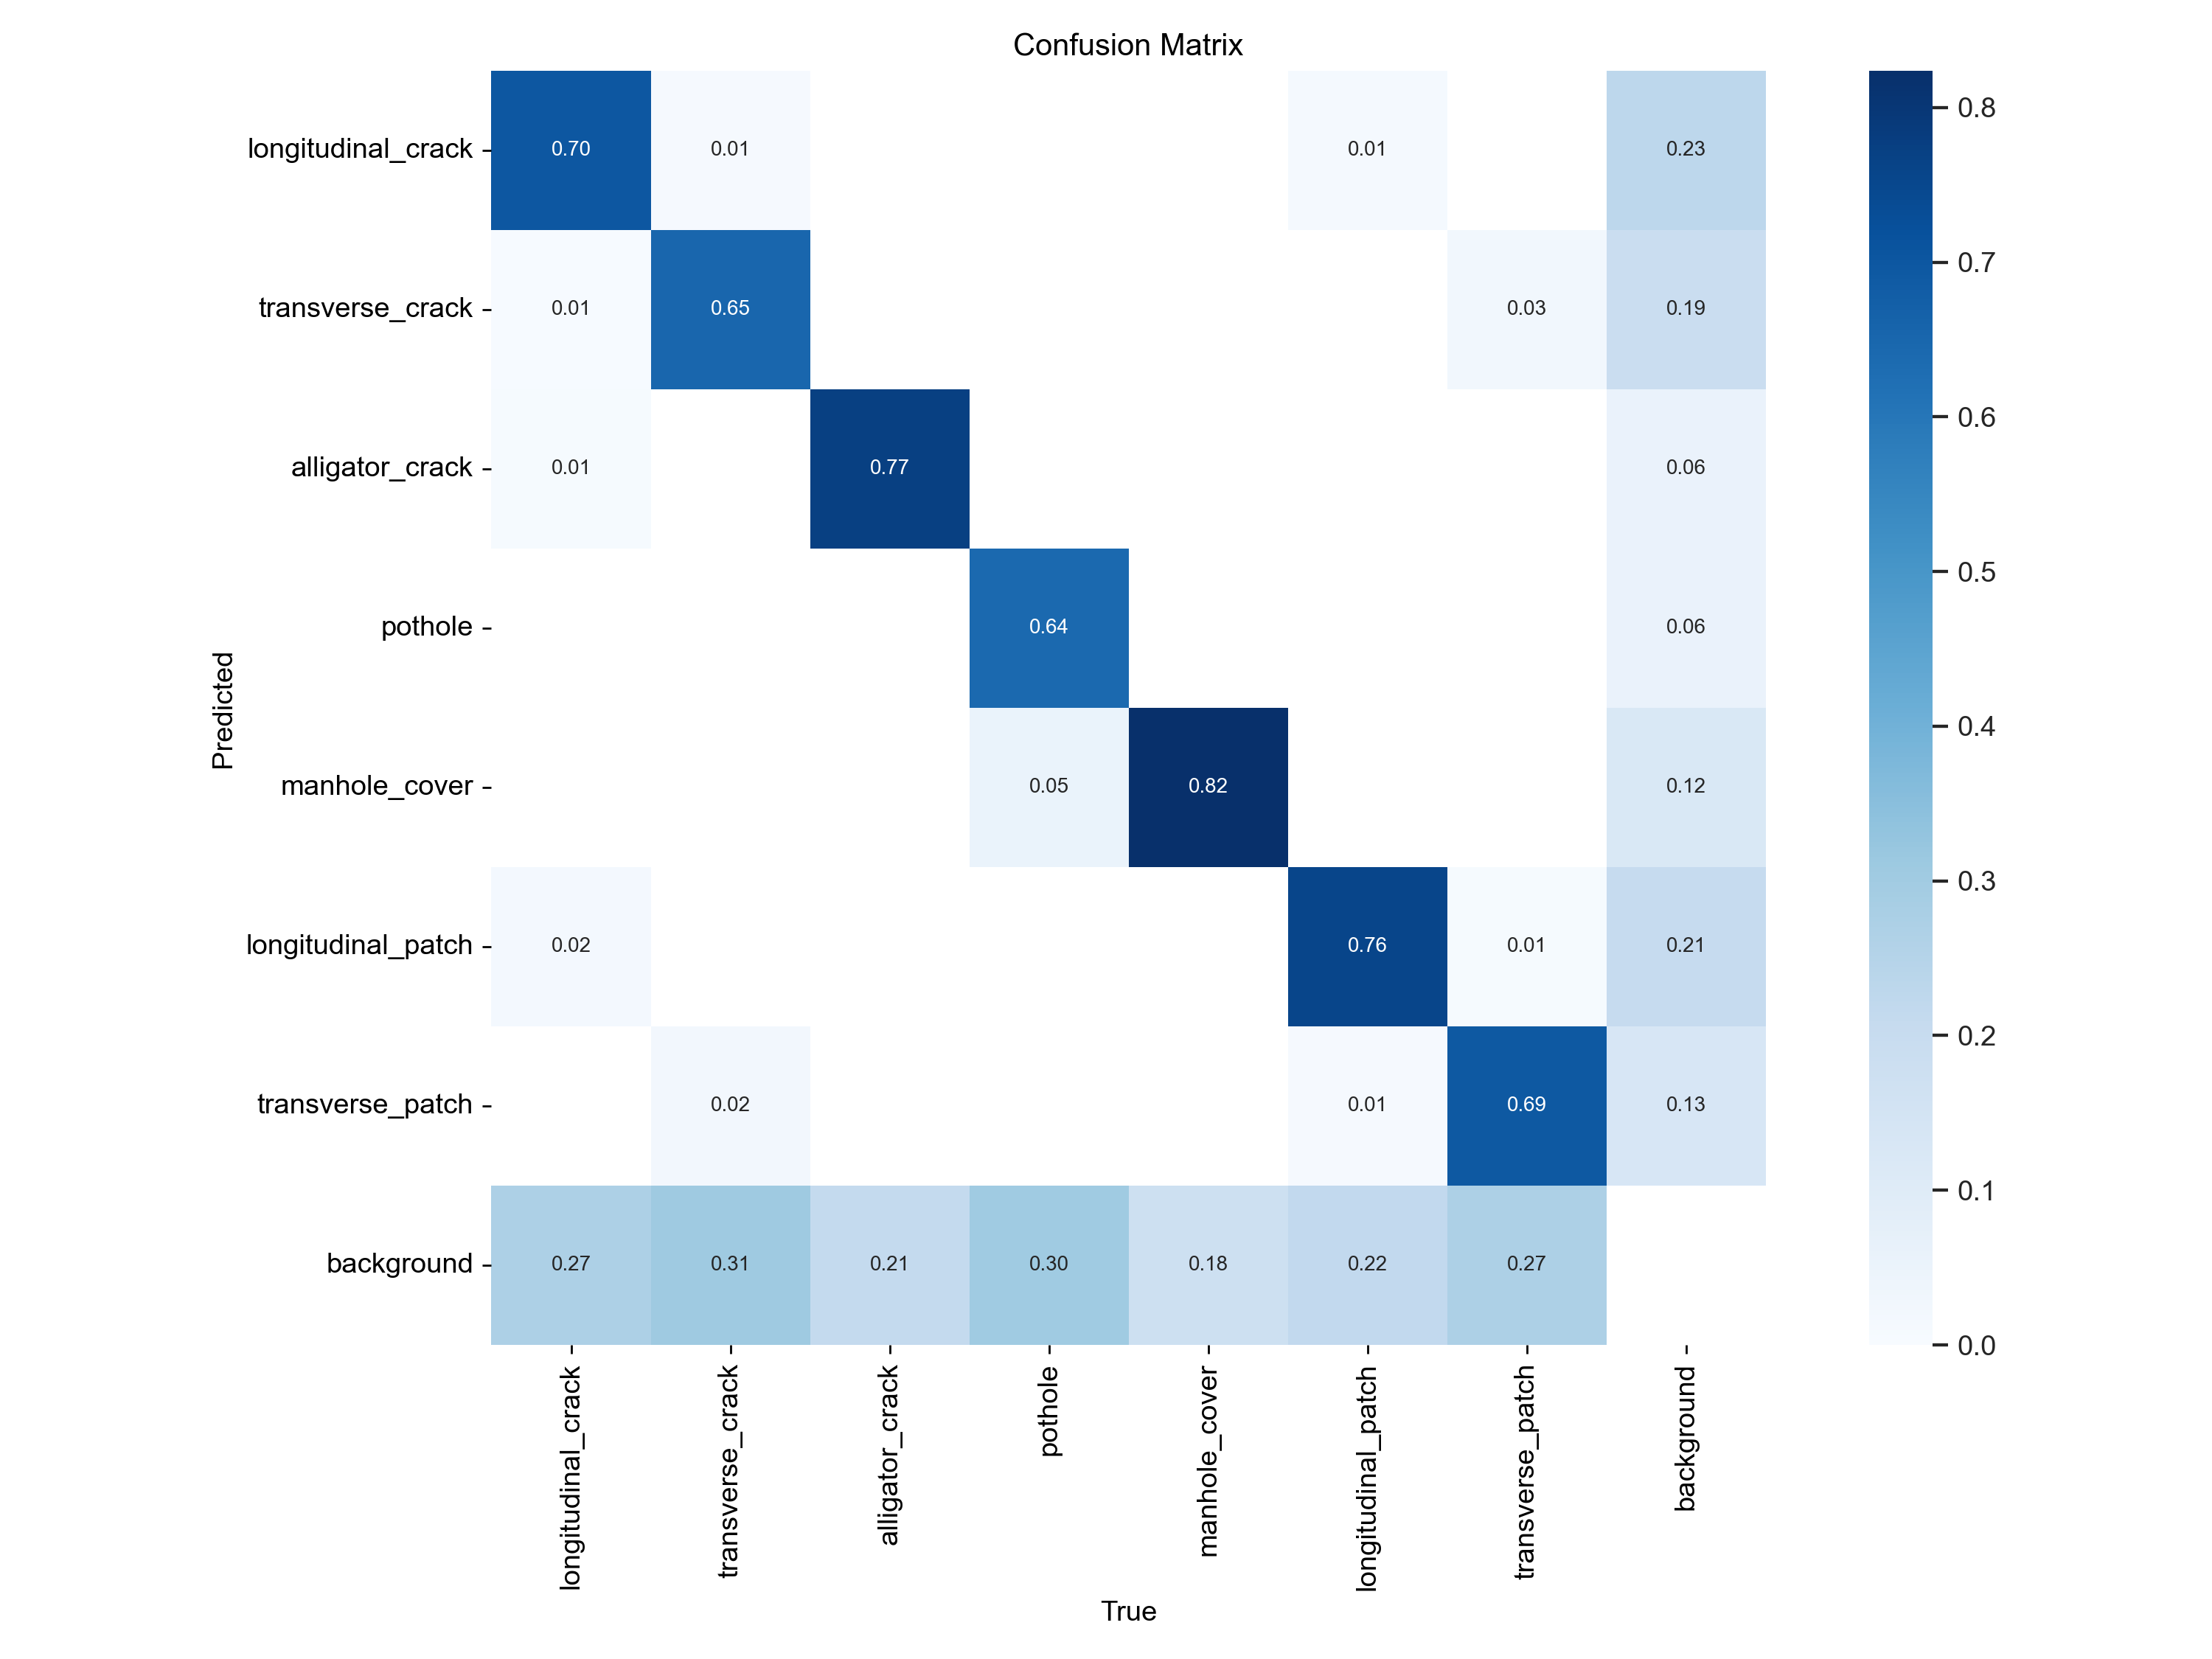

In [10]:
import glob, os
from IPython.display import Image, display

RUN = f'{DRIVE_DIR}/runs/{NAME}'
if not os.path.exists(RUN):   # fall back to the newest folder starting with NAME
    RUN = sorted(glob.glob(f'{DRIVE_DIR}/runs/{NAME}*'), key=os.path.getmtime)[-1]
print('Showing results from:', RUN)

for img, w in [('results.png', 900), ('confusion_matrix.png', 600)]:
    path = f'{RUN}/{img}'
    if os.path.exists(path):
        display(Image(path, width=w))
    else:
        print('Not found (run may have been interrupted):', path)

In [11]:
# Per-class table of the best checkpoint on the VALIDATION set (not test)
!python val.py --weights {RUN}/weights/best.pt --data data/svrdd.yaml --img 640 \
  --task val --project /content/tmp_val --name {NAME} --exist-ok

val: data=data/svrdd.yaml, weights=['/content/drive/MyDrive/svrdd/runs/baseline_s0/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=val, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=/content/tmp_val, name=baseline_s0, exist_ok=True, half=False, dnn=False
YOLOv5 🚀 2026-11-18 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)

Fusing layers... 
Model summary: 68 layers, 7,029,004 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/datasets/svrdd/splits/val.cache... 1000 images, 0 backgrounds, 0 corrupt
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 32/32 3.2it/s 10.0s
                   all       1000       2612      0.775      0.649      0.716      0.408
    longitudinal_crack       1000        588       0.75      0.642      0.693      0.423
      tra

In [12]:
# Shared experiment log
import pandas as pd
pd.read_csv(f'{DRIVE_DIR}/experiments.csv')

,date,who,name,status,branch,commit,hyp,seed,epochs,batch,gpu,minutes,best_epoch,P,R,mAP50,mAP50_95,notes
0,2026-11-18 20:27,Yiğit Emre Arıkan,baseline_s0,done,main,af93934,data/hyps/hyp.scratch-low.yaml,0,80,32,NVIDIA A100-SXM4-40GB,43.4,76,0.7799,0.6488,0.7161,0.4091,NaN


## 5. Test set evaluation (only at the very end!)

The test set is **only for the final models**. Never use it to choose settings or make decisions.

In [ ]:
!python val.py --weights {RUN}/weights/best.pt --data data/svrdd.yaml \
  --img 640 --task test --project {DRIVE_DIR}/test_results --name {NAME}

## 6. Sending the code changes to GitHub

Changes go to the **current branch** (BRANCH). Add only code files; data, `runs/` and `.pt` files stay on Drive.

When the work on your branch is finished, open a **Pull request** on GitHub (*Pull requests → New pull request*, base: `main`, compare: your branch). After a teammate checks it, click **Merge**. This way `main` always stays a working version.

In [ ]:
print(git('status', '--short').stdout or 'No changes.')

?? yolov5/data/svrdd.yaml



In [ ]:
FILES   = ['yolov5/utils/loss.py']        # list the files you changed
MESSAGE = 'Describe what you changed'

for f in FILES:
    git('add', f)
print(git('commit', '-m', MESSAGE, check=False).stdout)
print(git('push', '-q', 'origin', BRANCH, check=False).stderr or f'Pushed to {BRANCH}.')

On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	yolov5/data/svrdd.yaml

nothing added to commit but untracked files present (use "git add" to track)

Pushed to main.


## 7. Close the session

*Runtime → Disconnect and delete runtime*. Compute units are also used while the session is idle.

---
## APPENDIX A: One-time setup (one person, once)

Do **not** run again if it was already done.

**Checkpoint rule:** by default YOLOv5 picks the "best" model by 10% mAP50 + 90% mAP50:95. Our proposal says **mAP50:95 only**. This cell fixes the rule and pushes it to `main`. Run it with `BRANCH = 'main'`, **before the real baseline**.

In [3]:
path = f'{PROJECT}/yolov5/utils/metrics.py'
src = open(path).read()
old = 'w = [0.0, 0.0, 0.1, 0.9]'
new = 'w = [0.0, 0.0, 0.0, 1.0]'
if new in src:
    print('Already changed.')
else:
    assert src.count(old) == 1, 'Expected line not found; check utils/metrics.py by hand.'
    open(path, 'w').write(src.replace(old, new))
    git('add', 'yolov5/utils/metrics.py')
    git('commit', '-m', 'Select best checkpoint by validation mAP50:95 only (proposal rule)')
    print(git('push', '-q', 'origin', 'main', check=False).stderr or 'Pushed to main.')
!grep -n "w = \[" utils/metrics.py

Already changed.
21:    w = [0.0, 0.0, 0.0, 1.0]  # weights for [P, R, mAP50, mAP50-95]


**Save this notebook to the repo:** *File → Save a copy in GitHub* → your repo, branch `main`, path `notebooks/svrdd_main.ipynb`. Teammates open it from *File → Open notebook → GitHub*.

---
## APPENDIX B: Troubleshooting

Only if the dataset in `/content` looks broken or incomplete (e.g. missing districts). It deletes the extracted copy so section 2 extracts it again from Drive.

In [ ]:
!rm -rf /content/datasets/svrdd